In [1]:
import matplotlib.pyplot as plt
import numpy as np
from IPython.display import HTML
from matplotlib.animation import PillowWriter, FuncAnimation

In [2]:
# PHYSICAL CONSTANTS & SODIUM PARAMETERS
m_e = 9.109e-31  # Mass of an electron [kg]
q_e = 1.602e-19  # Elementary charge [C]
phi_sodium = 2.28  # Sodium work function [eV]
phi_joules = phi_sodium * q_e  # Convert work function to Joules

In [3]:
# Laser / Photon parameters (Blue Laser at 450 nm)
h = 6.626e-34  # Planck's constant [J*s]
c = 3.0e8  # Speed of light [m/s]
lam = 450e-9  # Wavelength in meters [m]
E_photon = (h * c) / lam  # Energy of incident photon [J]

In [4]:
# Einstein's Photoelectric Equation: K_max = E_photon - Work Function
K_max = max(0.0, E_photon - phi_joules)
v_max = np.sqrt(2 * K_max / m_e)  # Maximum initial velocity upon leaving plate [m/s]

In [5]:
# SIMULATION SETUP
plate_distance = 0.01  # Distance between plates = 1 cm [m]

# Strong retarding potential (negative voltage) to brake and reverse electrons
V_plate = -9.0  # Voltage [V]
E_field_magnitude = (V_plate / plate_distance)  # Uniform electric field magnitude [V/m]

n_electrons = 25  # Number of electrons simulated simultaneously
dt = 2.0e-11  # Time step size per frame [seconds]
n_steps = 700  # Total number of time steps (animation duration)

# Initialize array to track electrons: [x_pos, y_pos, v_x, v_y, active_status]
electrons = np.zeros((n_electrons, 5))
for i in range(n_electrons):
  electrons[i, 0] = 0.0  # All start at the emitter plate (x = 0)
  electrons[i, 1] = np.random.uniform(-0.003, 0.003)  # Slight spread along y-axis

  angle = np.random.uniform(-np.pi / 6, np.pi / 6)  # Narrow emission cone angle
  speed = v_max * np.random.uniform(1.2, 2.0) + 1.2e6
  electrons[i, 2] = speed * np.cos(angle)  # Initial x-velocity component (vx)
  electrons[i, 3] = speed * np.sin(angle)  # Initial y-velocity component (vy)
  electrons[i, 4] = 1.0  # Status 1.0 = Active particle

In [6]:
# TIME-STEPPING KINEMATICS LOOP
history = []  # List to store particle positions at each frame
for step in range(n_steps):
  history.append(electrons[:, :2].copy())  # Save current x,y coordinates for plotting

  for i in range(n_electrons):
    if electrons[i, 4] == 0:
      continue  # Skip particles that have already hit a wall

    # Calculate constant electrostatic force acceleration: a_x = (q * E) / m
    accel_x = (q_e * E_field_magnitude) / m_e
    accel_y = 0.0  # No external y-field, zero vertical acceleration

    # Update velocity components using Euler-Cromer integration method
    electrons[i, 2] += accel_x * dt  # v_x = v_x + (a_x * dt)
    electrons[i, 3] += accel_y * dt  # v_y = v_y + (a_y * dt)

    # Update spatial positions based on newly updated velocities
    electrons[i, 0] += electrons[i, 2] * dt  # x = x + (v_x * dt)
    electrons[i, 1] += electrons[i, 3] * dt  # y = y + (v_y * dt)

    # Check boundaries and collision conditions
    if electrons[i, 0] >= plate_distance:
      electrons[i, 0] = plate_distance
      electrons[i, 4] = 0  # Deactivate if it hits the collector plate
    elif electrons[i, 0] < 0:
      electrons[i, 0] = 0
      electrons[i, 4] = 0  # Deactivate if it turns back and hits emitter plate

findfont: Font family ['cmmi10'] not found. Falling back to DejaVu Sans.
findfont: Font family ['cmsy10'] not found. Falling back to DejaVu Sans.
findfont: Font family ['cmr10'] not found. Falling back to DejaVu Sans.
findfont: Font family ['cmtt10'] not found. Falling back to DejaVu Sans.
findfont: Font family ['cmti10'] not found. Falling back to DejaVu Sans.
findfont: Font family ['cmb10'] not found. Falling back to DejaVu Sans.
findfont: Font family ['cmss10'] not found. Falling back to DejaVu Sans.
findfont: Font family ['cmex10'] not found. Falling back to DejaVu Sans.


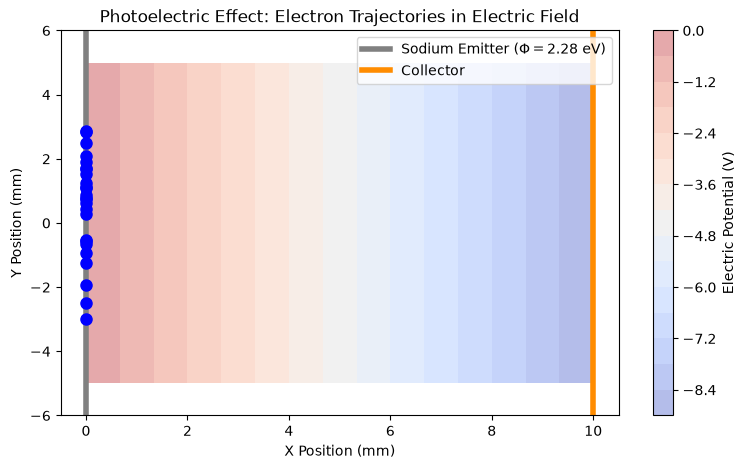

In [7]:
# ANIMATION & PLOT SETUP
fig, ax = plt.subplots(figsize=(9, 5))

# Create grid coordinates for background electric potential contour map
x_grid = np.linspace(0, plate_distance, 50)
y_grid = np.linspace(-0.005, 0.005, 50)
X, Y = np.meshgrid(x_grid, y_grid)
Potential = E_field_magnitude * X  # Linear voltage drop across the gap

contour = ax.contourf(X * 1000, Y * 1000, Potential, levels=15, cmap="coolwarm", alpha=0.4)
cbar = fig.colorbar(contour, ax=ax)
cbar.set_label("Electric Potential (V)")

# Draw physical boundary plates
ax.axvline(0, color="gray", linewidth=4, label="Sodium Emitter ($\Phi = 2.28$ eV)")
ax.axvline(plate_distance * 1000, color="darkorange", linewidth=4, label="Collector")

# Configure plot axis boundaries and labels (converted to millimeters)
ax.set_xlim(-0.5, (plate_distance * 1000) + 0.5)
ax.set_ylim(-6, 6)
ax.set_xlabel("X Position (mm)")
ax.set_ylabel("Y Position (mm)")
ax.set_title("Photoelectric Effect: Electron Trajectories in Electric Field")
ax.legend(loc="upper right")

# Initialize scatter plot object for animated electrons
(scat,) = ax.plot([], [], "bo", markersize=8, label="Electrons")

# Update function called sequentially for each animation frame
def update(frame_idx):
  pos = history[frame_idx]
  valid = pos[:, 0] >= 0
  scat.set_data(pos[valid, 0] * 1000, pos[valid, 1] * 1000)  # Update blue dot positions
  return (scat,)
# Compile frames into a FuncAnimation object
anim = FuncAnimation(fig, update, frames=len(history), interval=30, blit=True, repeat=True)

In [8]:
# EXPORT ANIMATION TO FILE
writer = PillowWriter(fps=30)
anim.save("photoelectric_simulation.gif", writer=writer)
plt.close(fig)
print("Animation successfully saved as 'photoelectric_simulation.gif'!")

Animation successfully saved as 'photoelectric_simulation.gif'!
